В этом файле мы будем улучшать метрики наших бейслайн моделей, будем проверять несколько гипотез:

1. StandardScaler,  может тогда линейная регрессия покажет метрики лучше
2. Логарифмирование числовых признаков и таргета также для улучшений метрик линейной модели 
3. Feature engineering на отдельных признаках

In [52]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [53]:
import numpy as np, pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from helper import load_clean_data, get_preprocessor, get_preprocessor_scaled ,evaluate_models_cv, get_preprocessor_log
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

SEED = 42

In [54]:
df = load_clean_data()
X, y = df.drop(columns=["annual_medical_cost"]), df["annual_medical_cost"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
cv_KFold = KFold(n_splits=5, shuffle=True, random_state=SEED)

models = [
    ("linear", LinearRegression()),
    ("tree", DecisionTreeRegressor(random_state=SEED, max_depth=4)),
    ("forest", RandomForestRegressor(random_state=SEED, n_jobs=-1)),
    ("lgbm", LGBMRegressor(random_state=SEED))
]

In [55]:
# Здесь наша точка отсчета 

initial_metrics = evaluate_models_cv(models, X_train, y_train, get_preprocessor(X_train), cv_KFold)
initial_metrics

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003528 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2394
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3014.539480


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003267 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2395
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3016.241110


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003076 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2393
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 2998.241664


...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003141 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2396
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3000.553826


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003126 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2395
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 2994.759390


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,root_mean_squared_error,mean_absolute_error,r2
linear,1863.791422,1130.888990,0.643259
tree,1878.868602,1122.180545,0.637467
forest,1740.619330,1000.195553,0.688796
lgbm,1727.496693,964.087789,0.693743


1. StandardScaler 

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002774 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2422
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3014.539480


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002678 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2422
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3016.241110


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002787 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2420
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 2998.241664


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002738 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2423
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 3000.553826


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002743 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2423
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 2994.759390


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


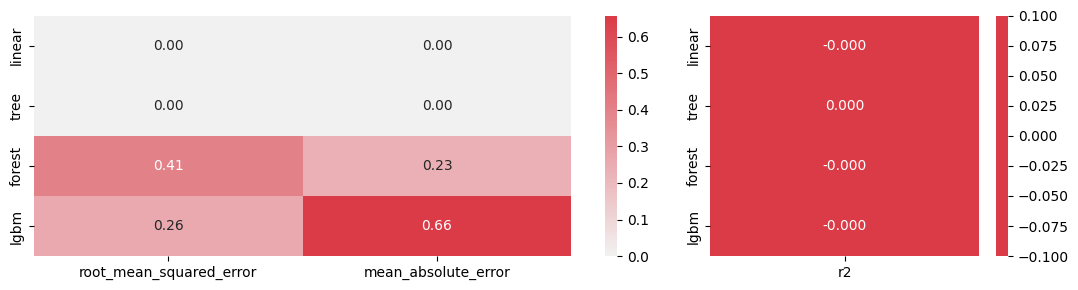

In [56]:
scaled_metrics = evaluate_models_cv(models, X_train, y_train, get_preprocessor_scaled(X_train), cv_KFold)

delta = (scaled_metrics - initial_metrics).round(3)

#Нужно разделить хитмапу, так как для MAE, MSE - одна цветовая палитра, для R2 - другая 
error_cols = ["root_mean_squared_error", "mean_absolute_error"]
r2_col = ["r2"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3),
                        gridspec_kw={"width_ratios": [2, 1]})

cmap_err = sns.diverging_palette(133, 10, as_cmap=True)   
sns.heatmap(delta[error_cols], annot=True, fmt=".2f", center=0,
            cmap=cmap_err, ax=axes[0])

cmap_r2 = sns.diverging_palette(10, 133, as_cmap=True)    
sns.heatmap(delta[r2_col], annot=True, fmt=".3f", center=0,
            cmap=cmap_r2, ax=axes[1])

plt.tight_layout()
plt.show()

StandardScaler не дал ни существенного улучшения метрик, ни существенного ухудшения

2. Логарифмирование числовых признаков и таргета также для улучшений метрик линейной модели 

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003343 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2394
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 7.644398


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003408 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2395
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 7.647167


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003618 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2393
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 7.642066


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003353 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2396
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 7.642930


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003323 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2395
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 67
[LightGBM] [Info] Start training from score 7.641804


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


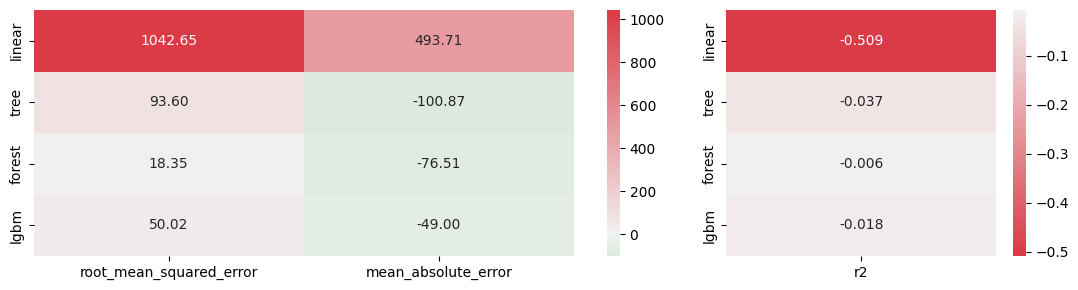

In [57]:
#оборачиваем таргет 
models_logtarget = [
    (name, TransformedTargetRegressor(regressor=m, func=np.log1p, inverse_func=np.expm1)) for name, m in models
]

#тут используется log-препроцессинг
log_metrics = evaluate_models_cv(models_logtarget, X_train, y_train, get_preprocessor_log(X_train), cv_KFold)

delta = (log_metrics - initial_metrics).round(3)

#Нужно разделить хитмапу, так как для MAE, MSE - одна цветовая палитра, для R2 - другая 
error_cols = ["root_mean_squared_error", "mean_absolute_error"]
r2_col = ["r2"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3),
                        gridspec_kw={"width_ratios": [2, 1]})

cmap_err = sns.diverging_palette(133, 10, as_cmap=True)   
sns.heatmap(delta[error_cols], annot=True, fmt=".2f", center=0,
            cmap=cmap_err, ax=axes[0])

cmap_r2 = sns.diverging_palette(10, 133, as_cmap=True)    
sns.heatmap(delta[r2_col], annot=True, fmt=".3f", center=0,
            cmap=cmap_r2, ax=axes[1])

plt.tight_layout()
plt.show()

Логарифмирование признаков и таргета ухудшило RMSE и R2 , однако улучшило MAE у большинства моделей. Если бы бизнес-метрикой был MAE, то тогда в логарифмировании еще был бы смысл, а так по сути логарифмирование нам не подходит

3. Feature engineering на отдельных признаках

Идеи:
pulse_pressure = systolic_bp - diastolic_bp - разница давления 
total_procedures = proc_imaging + proc_surgery + proc_physio + prc_consult + proc_lab - суммарное количество процедур 
avg_days_per_hosp = days_hospitalized_last_3yrs / hospitalizations_last_3yrs - средняя тяжеть госпитализации 

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003488 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2518
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 70
[LightGBM] [Info] Start training from score 3014.539480


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003460 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2518
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 70
[LightGBM] [Info] Start training from score 3016.241110


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003380 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2515
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 70
[LightGBM] [Info] Start training from score 2998.241664


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003542 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2518
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 70
[LightGBM] [Info] Start training from score 3000.553826


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003431 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2519
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 70
[LightGBM] [Info] Start training from score 2994.759390


/Users/karimildarovic/Задание регрессия/venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


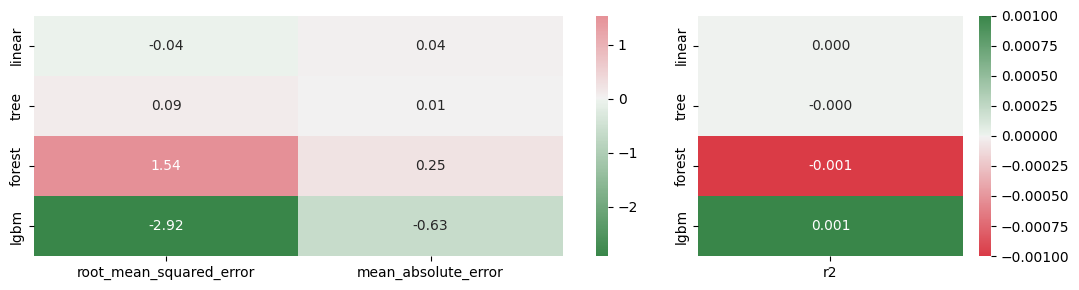

In [58]:
df["pulse_pressure"] = df["systolic_bp"] - df["diastolic_bp"]

df["total_procedures"] = (df["proc_imaging_count"] + df["proc_surgery_count"] + df["proc_physio_count"] + df["proc_consult_count"] 
                          + df["proc_lab_count"])

df["avg_days_per_hosp"] = np.where(df["hospitalizations_last_3yrs"] > 0, df["days_hospitalized_last_3yrs"] / df["hospitalizations_last_3yrs"], 0)

X, y = df.drop(columns=["annual_medical_cost"]), df["annual_medical_cost"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

fe_metrics = evaluate_models_cv(models, X_train, y_train, get_preprocessor(X_train), cv_KFold)
delta = (fe_metrics - initial_metrics).round(3)


error_cols = ["root_mean_squared_error", "mean_absolute_error"]
r2_col = ["r2"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3),
                        gridspec_kw={"width_ratios": [2, 1]})

cmap_err = sns.diverging_palette(133, 10, as_cmap=True)   
sns.heatmap(delta[error_cols], annot=True, fmt=".2f", center=0,
            cmap=cmap_err, ax=axes[0])

cmap_r2 = sns.diverging_palette(10, 133, as_cmap=True)    
sns.heatmap(delta[r2_col], annot=True, fmt=".3f", center=0,
            cmap=cmap_r2, ax=axes[1])

plt.tight_layout()
plt.show()

По сути глобально FE ничего не дела, все дельты в пределах шума

ВЫВОД:

Были проверены 3 гипотезы - масштабирование, лог признаков и таргета, feature engineering. Ни одна не улучшила baseline. Будем работать с baseline LGBM 